In [1]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,number_of_hadm,gender,age,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,icd_binary_scaled
0,10000980,2,1,75.0,169.0,69.0,1.0,0.0,0.0,7.0,163.0,0.0,0.0,0.0,0.666669
1,10002013,1,1,69.0,40.0,15.0,0.0,0.0,0.0,2.0,300.0,0.0,0.0,0.0,0.000001
2,10002155,1,1,69.0,276.0,106.0,4.0,0.0,0.0,8.0,140.0,0.0,0.0,0.0,0.000001
3,10004457,1,0,66.0,21.0,6.0,0.0,0.0,0.0,0.0,92.0,0.0,0.0,0.0,0.000650
4,10007058,1,0,48.0,112.0,42.0,2.0,0.0,0.0,2.0,111.0,0.0,0.0,0.0,0.000001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,1,1,71.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.166666
4379,19998597,1,1,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000080
4380,19998598,1,1,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.083332
4381,19998599,1,0,59.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000039


In [2]:
profile_df.drop(columns=['subject_id'],inplace=True) 
profile_df.drop(columns=['gender'],inplace=True) 
profile_df

,number_of_hadm,age,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,icd_binary_scaled
0,2,75.0,169.0,69.0,1.0,0.0,0.0,7.0,163.0,0.0,0.0,0.0,0.666669
1,1,69.0,40.0,15.0,0.0,0.0,0.0,2.0,300.0,0.0,0.0,0.0,0.000001
2,1,69.0,276.0,106.0,4.0,0.0,0.0,8.0,140.0,0.0,0.0,0.0,0.000001
3,1,66.0,21.0,6.0,0.0,0.0,0.0,0.0,92.0,0.0,0.0,0.0,0.000650
4,1,48.0,112.0,42.0,2.0,0.0,0.0,2.0,111.0,0.0,0.0,0.0,0.000001
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,1,71.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.166666
4379,1,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000080
4380,1,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.083332
4381,1,59.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000039


MinMax è preferibile per K-Means perché mette tutte le variabili nello stesso range [0,1], evitando che variabili con varianze più alte dominino la distanza Euclidea.

In [3]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X = scaler.fit_transform(profile_df.values)


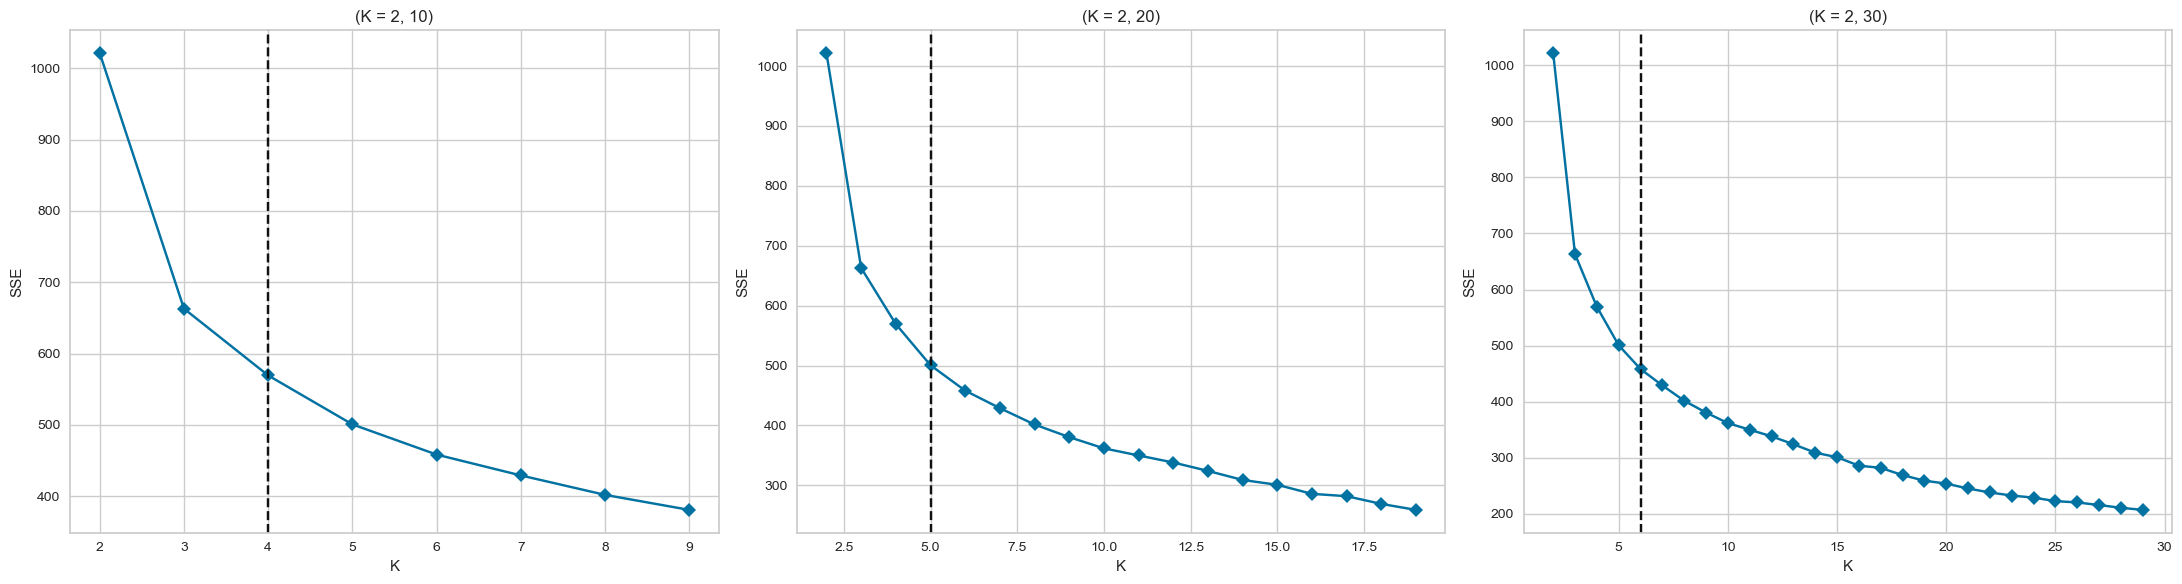

K suggeriti dal metodo elbow: [np.int64(4), np.int64(5), np.int64(6)]


In [4]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

random_state = 42  # fisso
# Range multipli da testare (2→10, 2→20, 2→30)
k_start = 2
k_max_list = [10, 20, 30]

model = KMeans(n_init=10, max_iter=100, random_state=random_state)

fig, axs = plt.subplots(1, len(k_max_list), figsize=(22, 6))

best_Ks = []

for i, k_max in enumerate(k_max_list):
    
    visualizer = KElbowVisualizer(
        model,
        k=(k_start, k_max),
        metric='distortion',    # SSE (inertia)
        timings=False,
        ax=axs[i]
    )

    visualizer.fit(X)  # <-- adattato al tuo codice: X = MinMax scaled profile_df
    
    axs[i].set_title(f'(K = {k_start}, {k_max})')
    axs[i].set_ylabel('SSE')
    axs[i].set_xlabel('K')
    
    elbow_k = visualizer.elbow_value_
    elbow_score = visualizer.elbow_score_

    if elbow_k is not None and elbow_k not in best_Ks:
        best_Ks.append(elbow_k)

plt.tight_layout()
plt.show()
plt.style.use("default") 


print("K suggeriti dal metodo elbow:", best_Ks)


In [5]:
#ciclo di valutazione delle metriche per k da 2 a 7
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import metrics

results = []

# Valuta k da 2 a 8
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state=random_state)
    kmeans.fit(X)
    labels = kmeans.labels_
    
    sse = kmeans.inertia_
    silhouette = silhouette_score(X, labels)
    db = metrics.davies_bouldin_score(X, labels)
    
    results.append([k, sse, silhouette, db])

results_df = pd.DataFrame(results, columns=["K", "SSE", "Silhouette", "DB_score"])
print(results_df)


   K          SSE  Silhouette  DB_score
0  2  1021.455524    0.575949  1.044998
1  3   662.955412    0.457429  0.896627
2  4   569.236520    0.370216  1.076212
3  5   500.567724    0.374111  1.261019
4  6   458.174473    0.353699  1.309401
5  7   428.946304    0.354577  1.251639
6  8   401.665670    0.252061  1.385161


Per stimare il numero ottimale di cluster K abbiamo utilizzato sia l’Elbow Method (distortion/SSE) tramite KElbowVisualizer, sia metriche di validazione interna (Silhouette e Davies–Bouldin Index) per K∈[2,30].
L’Elbow Method non mostra un gomito estremamente netto, ma indica che il miglior compromesso tra riduzione dell’errore e complessità del modello si colloca per K compresi approssimativamente tra 3 e 8; oltre K≈8 la curva della SSE diventa quasi piatta e i miglioramenti sono marginali.
Analizzando la Silhouette e il Davies–Bouldin Index, la qualità della partizione risulta massima per K=3: per K>3 la Silhouette tende a diminuire e il DB-index non migliora significativamente, mentre i cluster diventano progressivamente più frammentati e meno interpretabili.
Per questo motivo abbiamo scelto K=3 come valore finale: è coerente con la regione suggerita dall’Elbow Method e, allo stesso tempo, massimizza le metriche di qualità del clustering e l’interpretabilità clinica dei centroidi.

In [6]:
from sklearn.cluster import KMeans

k = 3
kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state=random_state)
kmeans.fit(X)

labels = kmeans.labels_

np.unique(labels, return_counts=True)


(array([0, 1, 2], dtype=int32), array([2858, 1172,  353]))

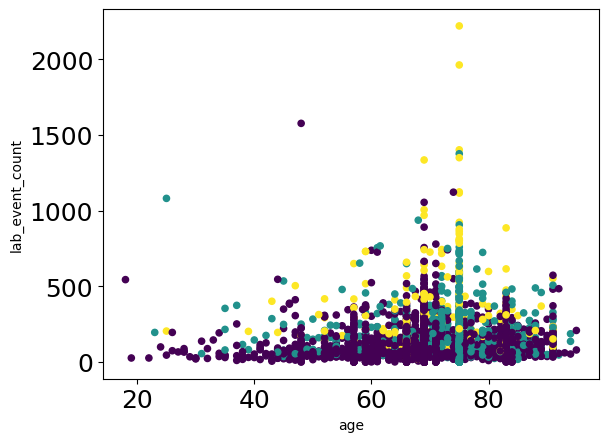

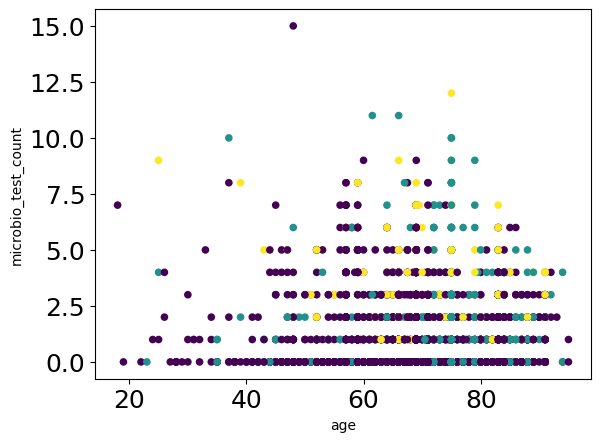

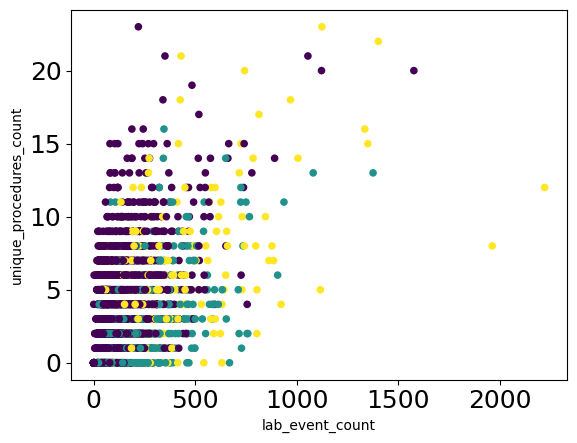

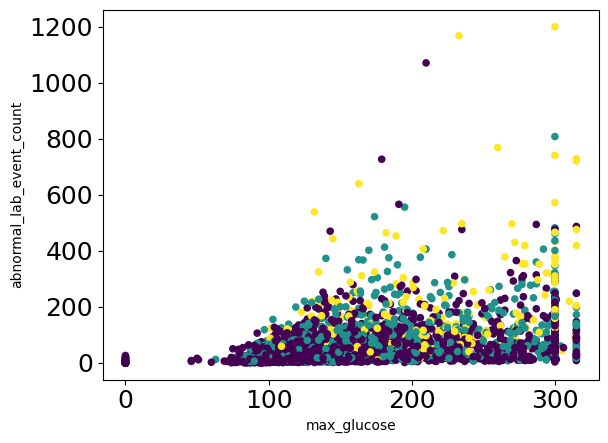

In [7]:
# Scatter 1
plt.scatter(profile_df['age'], profile_df['lab_event_count'], c=labels, s=20)
plt.xlabel('age')
plt.ylabel('lab_event_count')
plt.tick_params(labelsize=18)
plt.show()

# Scatter 2
plt.scatter(profile_df['age'], profile_df['microbio_test_count'], c=labels, s=20)
plt.xlabel('age')
plt.ylabel('microbio_test_count')
plt.tick_params(labelsize=18)
plt.show()

# Scatter 3
plt.scatter(profile_df['lab_event_count'], profile_df['unique_procedures_count'], 
            c=labels, s=20)
plt.xlabel('lab_event_count')
plt.ylabel('unique_procedures_count')
plt.tick_params(labelsize=18)
plt.show()

# Scatter 4
plt.scatter(profile_df['max_glucose'], profile_df['abnormal_lab_event_count'], 
            c=labels, s=20)
plt.xlabel('max_glucose')
plt.ylabel('abnormal_lab_event_count')
plt.tick_params(labelsize=18)
plt.show()


In [8]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers = pd.DataFrame(centers, columns=profile_df.columns)
centers


,number_of_hadm,age,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,icd_binary_scaled
0,1.053184,68.225682,108.457663,43.819104,1.014346,0.078027,0.094822,3.698390,146.965360,0.000496,0.000233,0.001866,0.028506
1,1.205631,74.126280,159.758532,72.197952,1.180887,0.116894,0.170648,1.606655,168.337884,0.000995,0.000711,0.003015,0.669497
2,1.218130,71.994334,280.070822,138.730878,2.883853,1.478754,10.555241,4.461756,193.399433,0.517328,0.191580,0.918540,0.257895


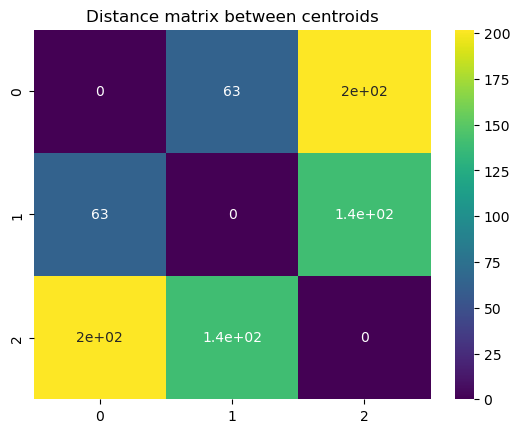

In [9]:
centers_np = centers.to_numpy() 

dist_matrix = np.zeros((k, k))
for i in range(k):
    for j in range(k):
        dist_matrix[i, j] = np.linalg.norm(centers_np[i] - centers_np[j])

sns.heatmap(dist_matrix, annot=True, cmap="viridis")
plt.title("Distance matrix between centroids")
plt.show()


La matrice delle distanze euclidee tra i centroidi (calcolati nello spazio originale delle feature) mostra tre gruppi chiaramente separati:

Cluster 0 e 1 → distanza ≈ 63 Rappresentano pazienti con profili simili, differenziati solo da un numero leggermente maggiore di esami/procedure

Cluster 1 e 2 → distanza ≈ 140. Indica un cambiamento più marcato

Cluster 0 e 2 → distanza ≈ 200. È la separazione più forte.

Queste distanze confermano che la partizione a 3 cluster identifica gruppi ben separati e interpretativamente significativi.

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_12223/1157595535.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


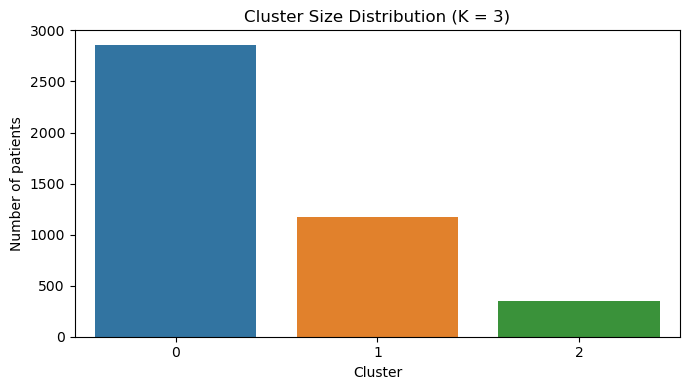

Cluster 0: 2858 pazienti
Cluster 1: 1172 pazienti
Cluster 2: 353 pazienti


In [10]:
# Distribuzione dei pazienti nei cluster
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 3)")
plt.tight_layout()
plt.show()

# Stampa numeri
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} pazienti")


### Distribuzione della cardinalità dei cluster

La distribuzione delle dimensioni dei cluster mostra una struttura non bilanciata, con un cluster di grandi dimensioni (Cluster 0), uno intermedio (Cluster 1) e un cluster più piccolo (Cluster 2). Questo comportamento è del tutto coerente con la natura dei dati: la maggior parte dei pazienti presenta un profilo clinico relativamente semplice, mentre solo una frazione più ridotta rientra in condizioni più complesse che richiedono un monitoraggio intensivo.

In particolare:

- **Cluster 0** (~2858 pazienti): pazienti a bassa complessità, con pochi esami e poche anomalie di laboratorio;
- **Cluster 1** (~1172 pazienti): profilo intermedio, con attività diagnostica moderata;
- **Cluster 2** (353 pazienti): gruppo più piccolo ma clinicamente rilevante, caratterizzato da un elevato numero di esami, anomalie e valori glicemici più alti.

La presenza di cluster sbilanciati non rappresenta un problema metodologico: riflette correttamente la reale distribuzione clinica dei casi, con pochi pazienti critici e molti pazienti più semplici.


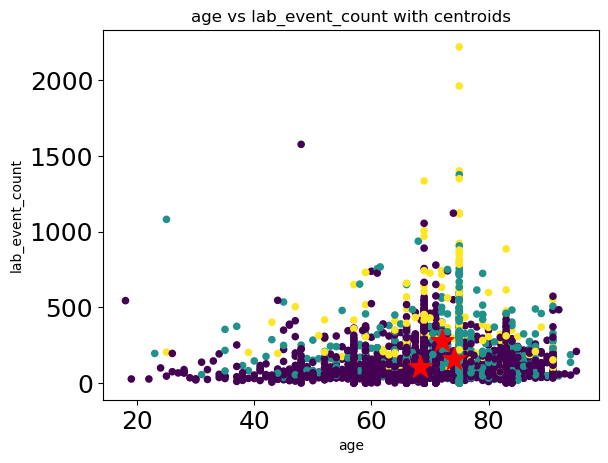

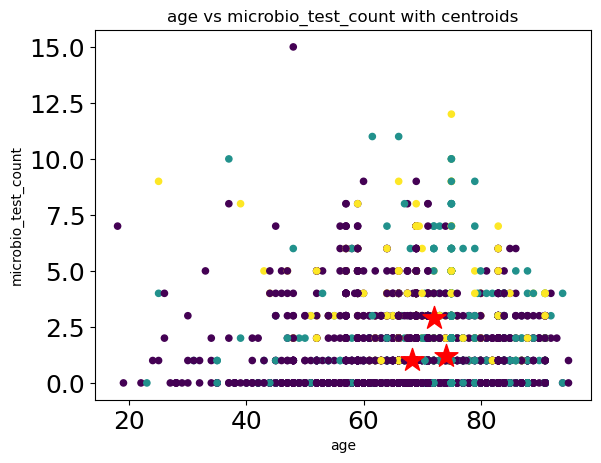

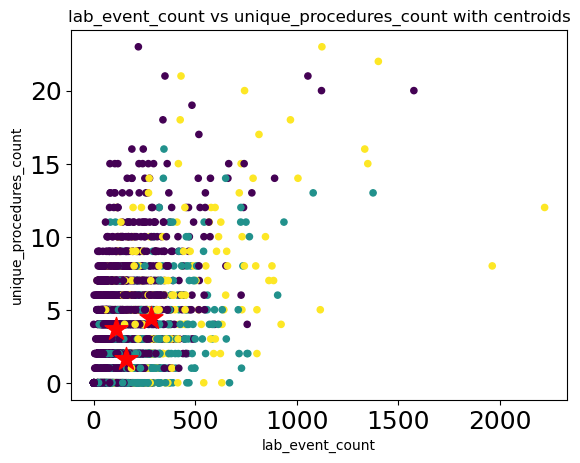

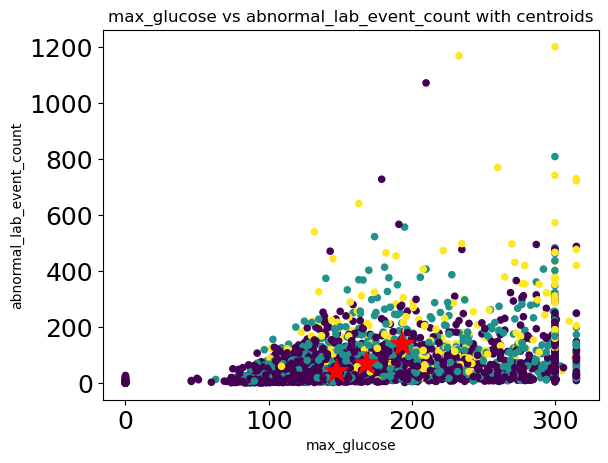

In [11]:
# 1) age vs lab_event_count
plt.scatter(profile_df['age'], profile_df['lab_event_count'], c=labels, s=20)

plt.scatter(
    centers['age'],
    centers['lab_event_count'],
    marker='*', s=300, c='red'
)

plt.xlabel('age')
plt.ylabel('lab_event_count')
plt.tick_params(labelsize=18)
plt.title("age vs lab_event_count with centroids")
plt.show()


# 2) age vs microbio_test_count
plt.scatter(profile_df['age'], profile_df['microbio_test_count'], c=labels, s=20)

plt.scatter(
    centers['age'],
    centers['microbio_test_count'],
    marker='*', s=300, c='red'
)

plt.xlabel('age')
plt.ylabel('microbio_test_count')
plt.tick_params(labelsize=18)
plt.title("age vs microbio_test_count with centroids")
plt.show()


# 3) lab_event_count vs unique_procedures_count
plt.scatter(profile_df['lab_event_count'], profile_df['unique_procedures_count'], c=labels, s=20)

plt.scatter(
    centers['lab_event_count'],
    centers['unique_procedures_count'],
    marker='*', s=300, c='red'
)

plt.xlabel('lab_event_count')
plt.ylabel('unique_procedures_count')
plt.tick_params(labelsize=18)
plt.title("lab_event_count vs unique_procedures_count with centroids")
plt.show()


# 4) max_glucose vs abnormal_lab_event_count
plt.scatter(profile_df['max_glucose'], profile_df['abnormal_lab_event_count'], c=labels, s=20)

plt.scatter(
    centers['max_glucose'],
    centers['abnormal_lab_event_count'],
    marker='*', s=300, c='red'
)

plt.xlabel('max_glucose')
plt.ylabel('abnormal_lab_event_count')
plt.tick_params(labelsize=18)
plt.title("max_glucose vs abnormal_lab_event_count with centroids")
plt.show()


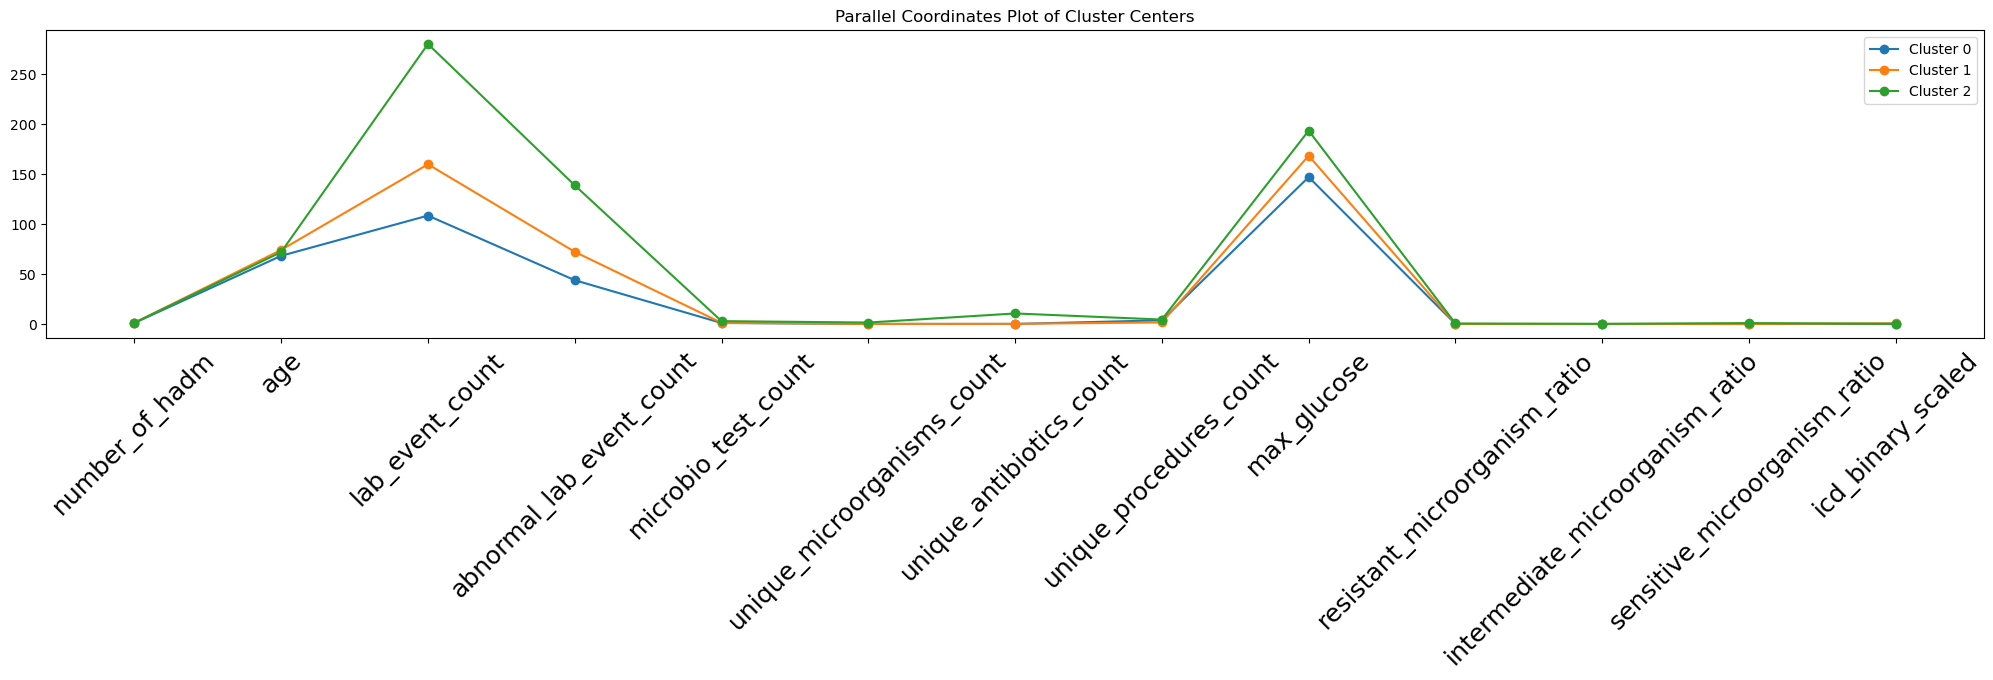

In [12]:
centers_np = centers.to_numpy()

plt.figure(figsize=(25, 4))
for i in range(len(centers_np)):
    plt.plot(centers_np[i], marker='o', label=f'Cluster {i}')

plt.xticks(range(len(profile_df.columns)), profile_df.columns, fontsize=18, rotation=45)
plt.legend()
plt.title("Parallel Coordinates Plot of Cluster Centers")
plt.show()


### Interpretazione

L’analisi dei centroidi tramite il parallel coordinates plot permette di interpretare i tre cluster
identificati da K-Means come tre gruppi di pazienti caratterizzati da un differente livello di
complessità clinica. Le linee che rappresentano i centroidi evidenziano infatti pattern molto netti:
un cluster si colloca costantemente ai valori più elevati delle variabili più significative, uno su
valori intermedi e uno sui valori più bassi. Questa struttura tri-modale rende i cluster facilmente
leggibili dal punto di vista clinico.

**Il primo gruppo** (Cluster 0 nel grafico), che mostra valori più bassi in quasi tutte le variabili,
raccoglie pazienti più giovani, con un numero ridotto di esami di laboratorio, poche anomalie rilevate
e valori glicemici più contenuti. Si tratta quindi di pazienti con un profilo di complessità ridotta,
che sembrano richiedere un monitoraggio meno intenso e procedure relativamente limitate.

**Il secondo gruppo** (Cluster 1) rappresenta una condizione intermedia: l’età è più elevata rispetto al
cluster precedente, il numero di lab events, di procedure e di test microbiologici aumenta in modo
sensibile, e anche i valori di glucose e abnormal lab events risultano più marcati. Questo cluster
sembra quindi raccogliere pazienti che richiedono un livello di attenzione diagnostica maggiore, pur
non raggiungendo i livelli di intensità clinica del gruppo più complesso.

**Il terzo gruppo** (Cluster 2) è invece quello che emerge come più critico. I centroidi mostrano picchi
molto chiari nelle variabili legate al carico diagnostico e clinico: il numero di esami di laboratorio
è il più alto, così come il numero di anomalie rilevate e i valori di max_glucose. Anche il numero di
procedure e l’intensità dei test microbiologici risultano superiori agli altri cluster. A questo si
aggiunge un’età media più elevata, coerentemente con un quadro clinico più delicato. Questo cluster
può essere interpretato come la fascia di pazienti con la maggiore complessità, che richiedono un
monitoraggio continuo e interventi diagnostici frequenti.

Nel complesso, i tre cluster possono essere letti come tre profili clinici distinti – **bassa,
intermedia e alta complessità** – e la loro separazione risulta coerente con ciò che emerge dalle
metriche interne di validazione. Questa struttura, facilmente interpretabile sia graficamente sia in
termini clinici, conferma la validità della scelta \(k=3\) e rafforza l’idea che il modello abbia
effettivamente colto pattern significativi all’interno della popolazione di pazienti analizzata.


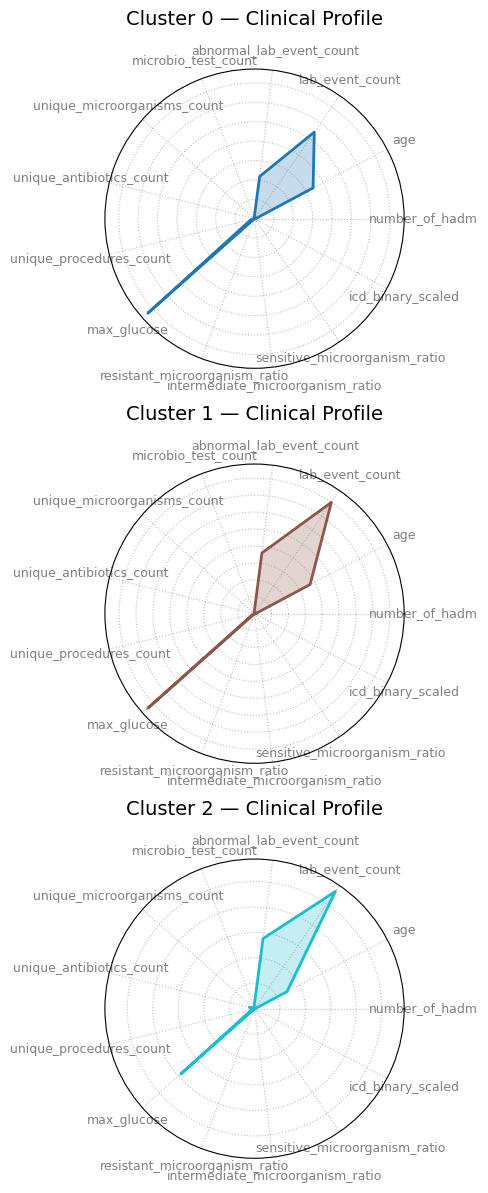

In [13]:
from math import pi

# Number of variables
N = len(profile_df.columns)
features_labels = profile_df.columns.tolist()

# Colors for clusters
colors = plt.cm.tab10(np.linspace(0, 1, len(centers)))

plt.figure(figsize=(12, 12))

for cluster_id in range(len(centers)):
    
    values = centers_np[cluster_id].tolist()
    values += values[:1]
    
    angles = [n / float(N) * 2*pi for n in range(N)]
    angles += angles[:1]
    
    ax = plt.subplot(3, 1, cluster_id + 1, polar=True)
    
    # Plot line
    ax.plot(angles, values, linewidth=2, color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.25, color=colors[cluster_id])
    
    # Axis labels (neutral, constant for all clusters)
    plt.xticks(angles[:-1], features_labels, size=9, color="grey")
    
    # Soft grid
    ax.grid(color="grey", linestyle="dotted", alpha=0.5)
    
    # Remove y-labels for readability
    ax.set_yticklabels([])
    
    # Title
    ax.set_title(f"Cluster {cluster_id} — Clinical Profile", size=14, y=1.12)

plt.tight_layout()
plt.show()


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_12223/403407787.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_12223/403407787.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_12223/403407787.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


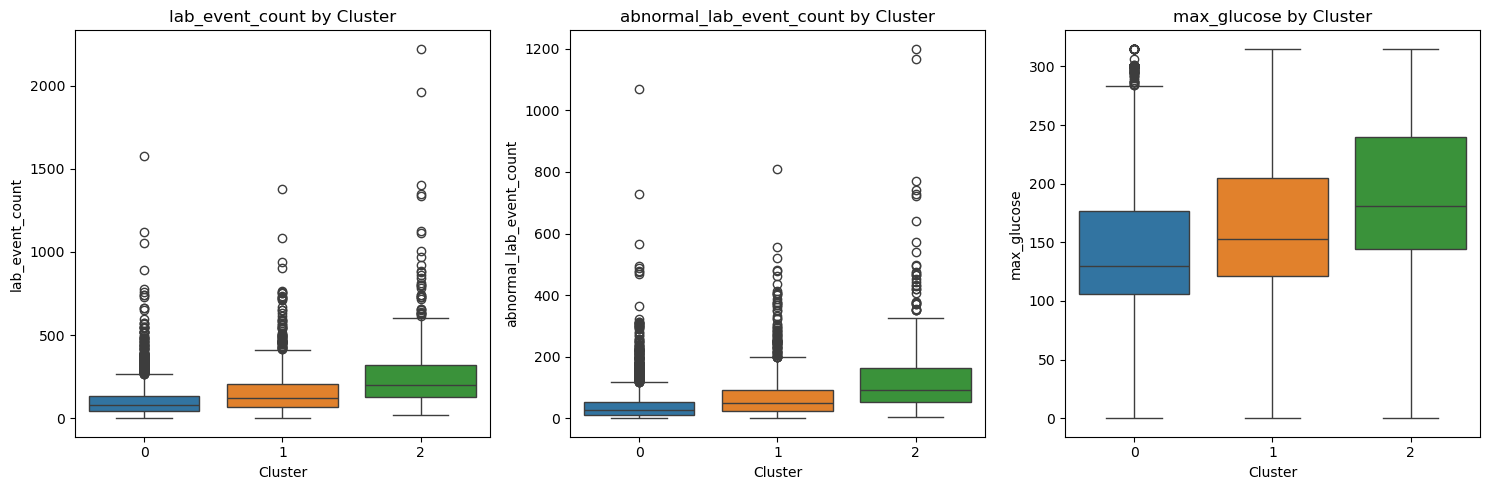

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Creiamo un DataFrame con i dati originali e il cluster assegnato
df_box = profile_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "abnormal_lab_event_count",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


I boxplot confermano con grande chiarezza la separazione tra i tre cluster individuati da K-Means. Per tutte e tre le variabili cliniche considerate, lab_event_count, abnormal_lab_event_count e max_glucose, emerge una struttura ordinata e coerente:

- **Cluster 0** presenta valori bassi in tutte le variabili, indicando pazienti con un profilo clinico semplice e un numero molto ridotto di esami eseguiti.

- **Cluster 1** mostra valori intermedi, con un’attività diagnostica maggiore e un livello di anomalie superiore rispetto al cluster precedente.

- **Cluster 2** evidenzia le mediane e i massimi più elevati, configurandosi come il gruppo di pazienti più complesso e clinicamente instabile, caratterizzato da un numero elevato di esami, molte anomalie di laboratorio e valori glicemici più alti.


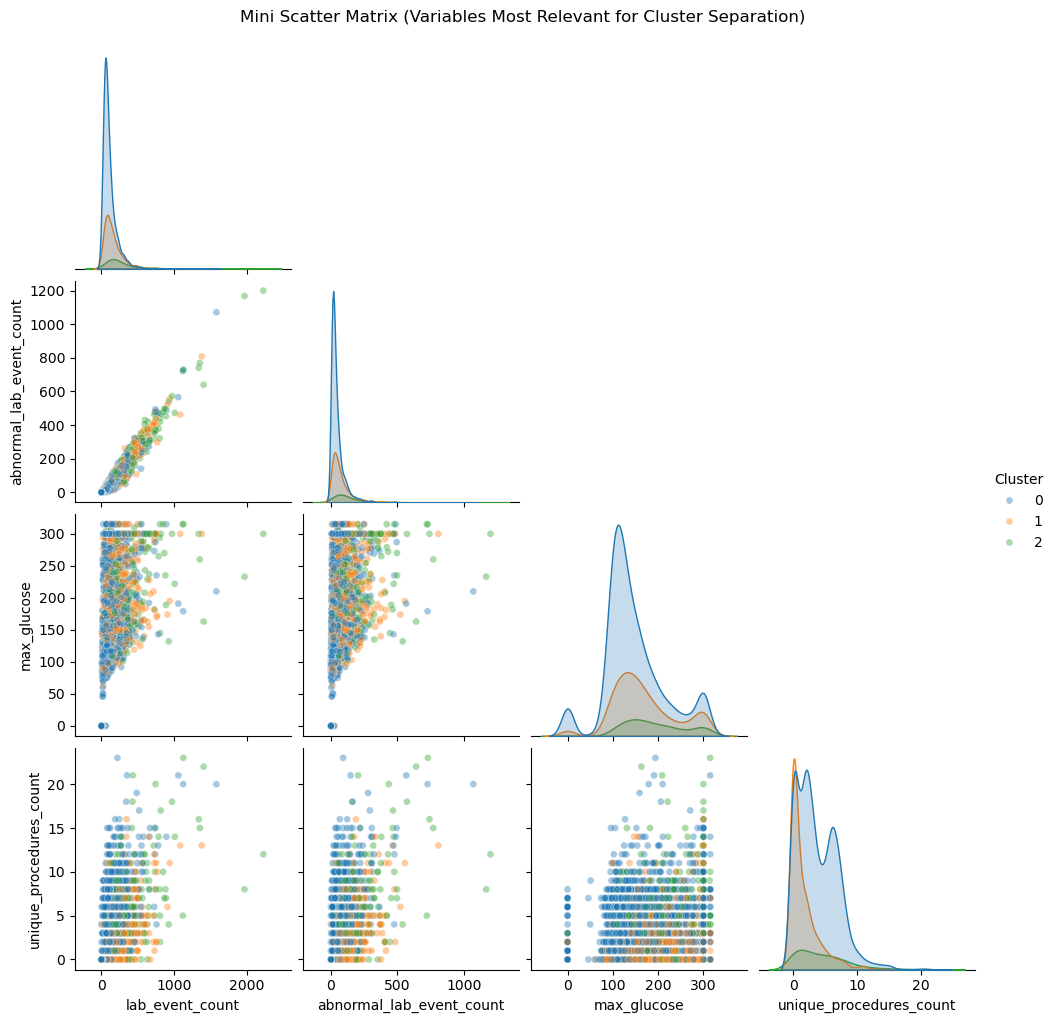

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

df_scatter = profile_df.copy()
df_scatter["Cluster"] = labels

vars_scatter = [
    "lab_event_count",
    "abnormal_lab_event_count",
    "max_glucose",
    "unique_procedures_count"
]

sns.pairplot(
    df_scatter[vars_scatter + ["Cluster"]],
    hue="Cluster",
    palette="tab10",
    corner=True,    # plotti solo metà matrice
    diag_kind="kde", # diagonale più elegante
    plot_kws={"alpha": 0.4, "s": 25}
)

plt.suptitle("Mini Scatter Matrix (Variables Most Relevant for Cluster Separation)", y=1.02)
plt.show()


### Mini Scatter Matrix
La scatter matrix costruita sulle quattro variabili clinicamente più informative (*lab_event_count*, *abnormal_lab_event_count*, *max_glucose* e
*unique_procedures_count*) conferma in modo visivo la separazione tra i tre cluster.

In particolare:

- **Cluster 0** (blu) si concentra sistematicamente nelle regioni a valori bassi: pochissimi esami, poche anomalie, glicemie più contenute e poche procedure.
Rappresenta il gruppo di pazienti a bassa complessità.

- **Cluster 1** (arancione) occupa la fascia intermedia in tutte le proiezioni, con un numero maggiore di esami e anomalie rispetto al cluster precedente ma senza raggiungere i livelli più elevati.
È il gruppo con complessità moderata.

- **Cluster 2** (verde) domina le regioni con valori più alti, mostrando molte anomalie, un numero elevato di esami, glicemia più alta e più procedure.
È il cluster dei pazienti più complessi e clinicamente instabili.


spiegazione del grafico per capire: Nei grafici diagonali della scatter matrix compaiono le curve di densità (KDE) delle
singole variabili per ciascun cluster. È normale che il cluster 2 presenti curve più
basse e più larghe: questo non indica valori inferiori, ma riflette il fatto che il
cluster contiene molti meno pazienti (353 contro oltre 2800 del cluster 0) e i valori
sono più dispersi. Le curve KDE sono infatti normalizzate: l’area totale è sempre 1,
indipendentemente dal numero di osservazioni. Per questo i cluster numerosi e con
valori concentrati producono curve più alte, mentre quelli meno frequenti o più
variabili mostrano curve più schiacciate. 

